# Linear and logistic regression

## Summary

**Linear regression** predicts a continuous target as a weighted sum of the input features plus a bias. It is fitted by minimising the mean squared error, which has a closed-form solution and is equivalent to maximum likelihood under Gaussian noise.

**Logistic regression** is used for binary classification. It takes the same weighted sum and passes it through a sigmoid to get the probability of the positive class, and it is fitted by maximising the likelihood, which is the same as minimising cross-entropy. It has no closed-form solution, but its loss is convex, so gradient descent or Newton's method finds the global optimum.

Both are generalised linear models, linear in their parameters, so linear regression fits only linear trends and logistic regression draws only linear decision boundaries, unless you add nonlinear features.

## Where it's used

| Who | Linear regression | Logistic regression |
|---|---|---|
| **Quants** | A stock's beta and alpha: regress its returns on the market's returns, or on several factors as in the Fama–French model. Hedge ratios between two assets. | Probability of default on credit desks. Probability that a price moves up rather than down. |
| **Data scientists** | Demand forecasting and price elasticity: the slope of a log–log regression is the elasticity. Regression adjustment (CUPED) to reduce variance in A/B tests. | Churn, fraud and spam prediction. Click-through rates in online advertising. Propensity scores in observational studies. |
| **Business analysts** | Driver analysis: which factors explain sales, costs or customer satisfaction, and by how much, e.g. how a store's revenue changes with footfall and staffing. Pricing decisions based on an estimated price elasticity. | Propensity models: how likely each customer is to churn, buy or respond to a campaign, to decide where to spend on retention or marketing. Win–loss analysis: which factors make a deal more likely to close. |
| **ML and research engineers** | The first baseline for any regression task. The output layer of a regression network is linear regression on the features the network has learned. | Linear probes, to test what a network's embeddings encode. Platt scaling, to turn a classifier's scores into calibrated probabilities. A classifier's output layer is logistic (softmax) regression on learned features. |
| **Medicine and economics** | Effect sizes with controls, e.g. how wages change with years of education, holding experience fixed. | Clinical risk scores. Effects are reported as odds ratios: increasing feature $j$ by one unit multiplies the odds by $e^{w_j}$. |

**Why they're still used when bigger models exist:** the coefficients can be read directly, which regulators, doctors and economists need; training is fast and the loss is convex, so the result is reliable; and they are the baseline any more complex model has to beat.

## Intuition

**Linear regression** fits a line (or, with more features, a plane) through a cloud of points so that the points are, on average, as close to it as possible in the vertical direction. Each weight says how much the prediction changes when that feature increases by one unit and the others stay fixed. Because the misses are squared, one point far from the line costs much more than several points slightly off it, so outliers pull the line towards themselves.

**Logistic regression** draws a line (or plane) through feature space that separates the two classes. The weighted sum tells you which side of that boundary a point is on, and how far from it. The sigmoid squashes this score into a probability: points far on one side get a probability close to 1, points far on the other side close to 0, and points on the boundary get 0.5. The size of the weights sets how sharp the transition is:

- **Small weights** give a gentle slope and cautious probabilities.
- **Large weights** give a steep slope and confident probabilities.

Training pushes the probabilities towards the true labels. Cross-entropy barely penalises confident correct predictions but penalises confident wrong ones very heavily. If the two classes can be separated perfectly, the model can always lower the loss by making the transition steeper, so without regularisation the weights grow forever.

**Why not use linear regression for classification?** Its predictions are not limited to between $0$ and $1$, so they can't be read as probabilities, and a point far on the correct side of the boundary still adds to the loss and drags the line towards it.

## Mathematical formulation

**Notation.** $n$ samples and $d$ features. $\mathbf{X} \in \mathbb{R}^{n \times d}$ is the design matrix with rows $\mathbf{x}_i^\top$, and $\mathbf{w} \in \mathbb{R}^d$ are the weights. The bias is absorbed by appending a column of ones to $\mathbf{X}$, so a prediction is $\mathbf{w}^\top \mathbf{x}_i$. Bold letters are vectors and matrices; $y_i$, $p_i$ and $z_i$ are single numbers.

Both models are worked through in the same four steps: model, loss, gradient, solving it.

### Linear regression

**1. Model.** Targets are real numbers, $y_i \in \mathbb{R}$, and the prediction is linear in the features:

$$
\hat{y}_i = \mathbf{w}^\top \mathbf{x}_i
$$

**2. Loss.** The mean squared error, written as a norm and then expanded:

$$
\begin{aligned}
L(\mathbf{w}) &= \frac{1}{n} \lVert \mathbf{y} - \mathbf{X}\mathbf{w} \rVert_2^2 \\
&= \frac{1}{n} \left( \mathbf{y}^\top \mathbf{y} - 2 \mathbf{w}^\top \mathbf{X}^\top \mathbf{y} + \mathbf{w}^\top \mathbf{X}^\top \mathbf{X} \mathbf{w} \right)
\end{aligned}
$$

**3. Gradient.** Differentiating the expanded form term by term:

$$
\nabla_{\mathbf{w}} L = \frac{2}{n} \mathbf{X}^\top \left( \mathbf{X} \mathbf{w} - \mathbf{y} \right)
$$

**4. Solving it.** Setting the gradient to zero gives the normal equations. If $\mathbf{X}$ has full column rank, they have a unique solution:

$$
\mathbf{X}^\top \mathbf{X} \mathbf{w}^* = \mathbf{X}^\top \mathbf{y} \quad \Longrightarrow \quad \mathbf{w}^* = (\mathbf{X}^\top \mathbf{X})^{-1} \mathbf{X}^\top \mathbf{y}
$$

It can also be solved iteratively with gradient descent, $\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla_{\mathbf{w}} L$.

**Side note: geometry.** The residual $\mathbf{y} - \mathbf{X}\mathbf{w}^*$ is orthogonal to every column of $\mathbf{X}$, so the prediction $\mathbf{X}\mathbf{w}^*$ is the projection of $\mathbf{y}$ onto the column space of $\mathbf{X}$.

**Side note: maximum likelihood.** Assume $y_i = \mathbf{w}^\top \mathbf{x}_i + \epsilon_i$ with independent noise $\epsilon_i \sim \mathcal{N}(0, \sigma^2)$. Adding a constant to Gaussian noise just shifts its centre, so $y_i \sim \mathcal{N}(\mathbf{w}^\top \mathbf{x}_i, \sigma^2)$, with density

$$
p(y_i \mid \mathbf{x}_i, \mathbf{w}) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{(y_i - \mathbf{w}^\top \mathbf{x}_i)^2}{2\sigma^2} \right)
$$

The noise terms are independent, so the likelihood of all $n$ targets is the product of these densities. The log turns the product into a sum and cancels the $\exp$:

$$
\log p(\mathbf{y} \mid \mathbf{X}, \mathbf{w}) = \sum_{i=1}^{n} \log p(y_i \mid \mathbf{x}_i, \mathbf{w}) = -\frac{n}{2} \log(2\pi\sigma^2) - \frac{1}{2\sigma^2} \sum_{i=1}^{n} (y_i - \mathbf{w}^\top \mathbf{x}_i)^2
$$

The first term doesn't depend on $\mathbf{w}$, and the second is a negative constant times the sum of squared errors. So maximising the likelihood is the same as minimising the squared error.

### Logistic regression

**1. Model.** Targets are class labels, $y_i \in \lbrace 0, 1 \rbrace$. The prediction is the probability of class 1: the linear score $z_i$ passed through the sigmoid:

$$
p_i = P(y_i = 1 \mid \mathbf{x}_i) = \sigma(z_i), \qquad z_i = \mathbf{w}^\top \mathbf{x}_i, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}
$$

**2. Loss.** Each label is Bernoulli, $p(y_i \mid \mathbf{x}_i) = p_i^{y_i} (1 - p_i)^{1 - y_i}$, so the mean negative log-likelihood is the binary cross-entropy:

$$
L(\mathbf{w}) = -\frac{1}{n} \sum_{i=1}^{n} \left[ y_i \log p_i + (1 - y_i) \log (1 - p_i) \right]
$$

**3. Gradient.** Using $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, the derivative of each term with respect to its score $z_i$ simplifies to $p_i - y_i$, so

$$
\nabla_{\mathbf{w}} L = \frac{1}{n} \mathbf{X}^\top (\mathbf{p} - \mathbf{y})
$$

This has the same form as the linear regression gradient: the input times (prediction minus target).

**4. Solving it.** Setting the gradient to zero gives $\mathbf{X}^\top (\sigma(\mathbf{X}\mathbf{w}) - \mathbf{y}) = \mathbf{0}$, which is nonlinear in $\mathbf{w}$, so there is no closed-form solution. The Hessian

$$
\mathbf{H} = \frac{1}{n} \mathbf{X}^\top \mathbf{S} \mathbf{X}, \qquad \mathbf{S} = \operatorname{diag}\big( p_i (1 - p_i) \big)
$$

is positive semi-definite, so the loss is convex and any local minimum is a global one. It is minimised iteratively:

$$
\text{gradient descent: } \mathbf{w} \leftarrow \mathbf{w} - \eta \nabla_{\mathbf{w}} L, \qquad \text{Newton's method: } \mathbf{w} \leftarrow \mathbf{w} - \mathbf{H}^{-1} \nabla_{\mathbf{w}} L
$$

**Side note: why it is called regression.** Inverting the sigmoid shows that the log-odds is linear in $\mathbf{x}_i$:

$$
\log \frac{p_i}{1 - p_i} = \mathbf{w}^\top \mathbf{x}_i
$$

So logistic regression is a linear regression on the log-odds. It only becomes a classifier when you threshold $p_i$, usually at 0.5.

## Implementation

Each function implements one equation from the section above. `X` always includes the column of ones added by `add_bias`.

In [1]:
import numpy as np


def add_bias(X):
    """Append a column of ones, so the bias is learned as the last weight."""
    return np.hstack([X, np.ones((X.shape[0], 1))])


def gradient_descent(loss, grad, w0, lr, n_steps):
    """Plain gradient descent. Returns the final weights and the loss at every step."""
    w = w0.copy()
    losses = [loss(w)]
    for _ in range(n_steps):
        w = w - lr * grad(w)
        losses.append(loss(w))
    return w, np.array(losses)


# Linear regression

def mse(X, y, w):
    """L(w) = (1/n) ||y - Xw||^2"""
    r = y - X @ w
    return r @ r / len(y)


def mse_grad(X, y, w):
    """grad L = (2/n) X^T (Xw - y)"""
    return 2 / len(y) * X.T @ (X @ w - y)


def linreg_closed_form(X, y):
    """Solve the normal equations X^T X w = X^T y, without forming the inverse."""
    return np.linalg.solve(X.T @ X, X.T @ y)


# Logistic regression

def sigmoid(z):
    # Same as 1 / (1 + exp(-z)), but exp never overflows for large |z|.
    return 0.5 * (1 + np.tanh(0.5 * z))


def bce(X, y, w):
    """Binary cross-entropy, written in terms of the score z = Xw.

    -[y log p + (1 - y) log(1 - p)] simplifies to log(1 + e^z) - y z,
    which avoids log(0) when p rounds to exactly 0 or 1.
    """
    z = X @ w
    return np.mean(np.logaddexp(0, z) - y * z)


def bce_grad(X, y, w):
    """grad L = (1/n) X^T (p - y)"""
    return X.T @ (sigmoid(X @ w) - y) / len(y)


def bce_hessian(X, w):
    """H = (1/n) X^T S X, with S = diag(p (1 - p))"""
    p = sigmoid(X @ w)
    return (X.T * (p * (1 - p))) @ X / len(X)


def logreg_newton(X, y, n_steps=25, tol=1e-10):
    """Newton's method: w <- w - H^{-1} grad L. Returns the weights and the loss at every step."""
    w = np.zeros(X.shape[1])
    losses = [bce(X, y, w)]
    for _ in range(n_steps):
        step = np.linalg.solve(bce_hessian(X, w), bce_grad(X, y, w))
        w = w - step
        losses.append(bce(X, y, w))
        if np.linalg.norm(step) < tol:
            break
    return w, np.array(losses)


def predict_proba(X, w):
    return sigmoid(X @ w)


def predict_class(X, w, threshold=0.5):
    return (predict_proba(X, w) >= threshold).astype(int)

## Experiments

Five short experiments on synthetic data, so the true answer is known. Each one has its own plot, with the takeaway below it.

In [2]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

# Linear regression data: one feature, y = 1.5 x + 2 + noise
x = rng.uniform(-3, 3, size=50)
y = 1.5 * x + 2 + rng.normal(size=50)
X = add_bias(x[:, None])

# Logistic regression data: two overlapping Gaussian clouds, and the same clouds moved far apart
n = 100
yc = np.repeat([0, 1], n)
Xc = np.vstack([rng.normal([-1, -1], 1.0, size=(n, 2)), rng.normal([1, 1], 1.0, size=(n, 2))])
Xs = np.vstack([rng.normal([-3, -3], 1.0, size=(n, 2)), rng.normal([3, 3], 1.0, size=(n, 2))])
Xcb, Xsb = add_bias(Xc), add_bias(Xs)

### 1. One outlier moves the line

Fit a line to 50 points from $y = 1.5x + 2$ plus noise, then add a single outlier and fit again.

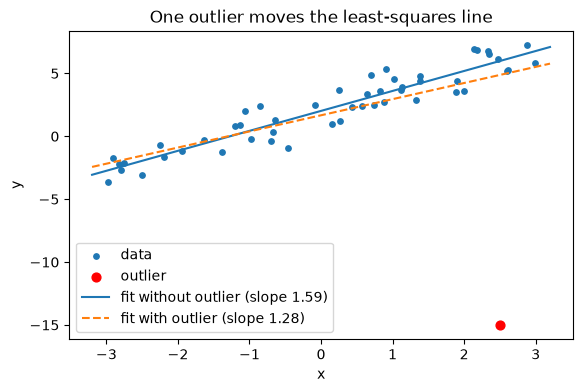

In [3]:
w_clean = linreg_closed_form(X, y)
x_out, y_out = np.append(x, 2.5), np.append(y, -15.0)
w_outlier = linreg_closed_form(add_bias(x_out[:, None]), y_out)

grid = np.linspace(-3.2, 3.2, 2)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(x, y, s=15, label="data")
ax.scatter([2.5], [-15.0], s=40, color="red", label="outlier")
ax.plot(grid, w_clean[0] * grid + w_clean[1], label=f"fit without outlier (slope {w_clean[0]:.2f})")
ax.plot(grid, w_outlier[0] * grid + w_outlier[1], "--", label=f"fit with outlier (slope {w_outlier[0]:.2f})")
ax.set(title="One outlier moves the least-squares line", xlabel="x", ylabel="y")
ax.legend()
plt.show()

Without the outlier, the fit is close to the true slope of 1.5. The outlier is 21 units below the line, so its squared error (about 440) is nearly nine times the squared errors of all the other points combined, and least squares tilts the line towards it. A loss that grows more slowly for large errors, such as the absolute error, would be pulled much less.

### 2. The learning rate

Run gradient descent on the same data with four learning rates, given as fractions of $\eta_{\max} = 2 / \lambda_{\max}$, where $\lambda_{\max}$ is the largest eigenvalue of the Hessian $\frac{2}{n} \mathbf{X}^\top \mathbf{X}$.

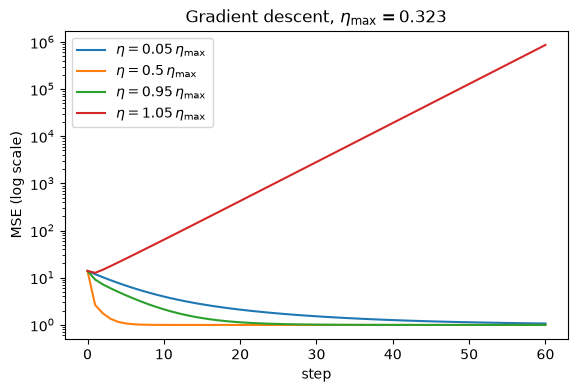

In [4]:
lr_max = 2 / np.linalg.eigvalsh(2 / len(y) * X.T @ X).max()

fig, ax = plt.subplots(figsize=(6.5, 4))
for frac in [0.05, 0.5, 0.95, 1.05]:
    _, losses = gradient_descent(lambda w: mse(X, y, w), lambda w: mse_grad(X, y, w),
                                 np.zeros(2), lr=frac * lr_max, n_steps=60)
    ax.semilogy(losses, label=rf"$\eta = {frac}\,\eta_{{\max}}$")
ax.set(title=rf"Gradient descent, $\eta_{{\max}} = {lr_max:.3f}$", xlabel="step", ylabel="MSE (log scale)")
ax.legend()
plt.show()

Each step multiplies the error along the steepest direction by $1 - \eta \lambda_{\max}$, so gradient descent converges only if $\eta < \eta_{\max}$. At $0.5 \eta_{\max}$ that factor is 0 and convergence is fastest; at $0.95 \eta_{\max}$ it is −0.9, so the weights zig-zag and progress slows; at $1.05 \eta_{\max}$ it is −1.1 and the loss explodes. The runs that converge level off at an MSE of about 1, the variance of the noise.

### 3. The decision boundary

Fit logistic regression with Newton's method to the two overlapping clouds, and colour the plane by the predicted probability.

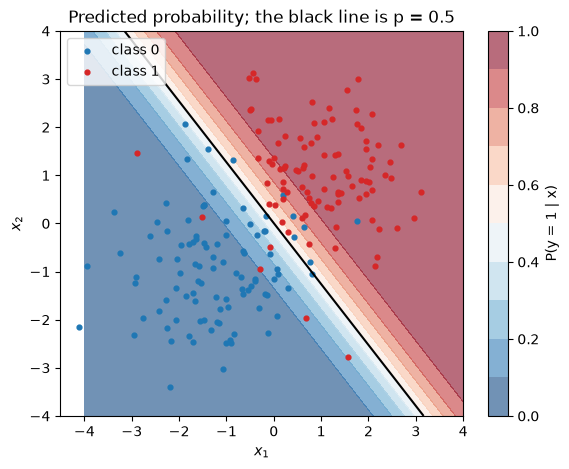

In [5]:
w_newton, newton_losses = logreg_newton(Xcb, yc)

g1, g2 = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-4, 4, 200))
proba = predict_proba(add_bias(np.column_stack([g1.ravel(), g2.ravel()])), w_newton).reshape(g1.shape)

fig, ax = plt.subplots(figsize=(6.5, 5))
contour = ax.contourf(g1, g2, proba, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.6)
ax.contour(g1, g2, proba, levels=[0.5], colors="black")
ax.scatter(*Xc[yc == 0].T, s=12, color="tab:blue", label="class 0")
ax.scatter(*Xc[yc == 1].T, s=12, color="tab:red", label="class 1")
fig.colorbar(contour, ax=ax, label="P(y = 1 | x)")
ax.set(title="Predicted probability; the black line is p = 0.5", xlabel="$x_1$", ylabel="$x_2$")
ax.legend(loc="upper left")
plt.show()

The black line is where $p = 0.5$, which is where $\mathbf{w}^\top \mathbf{x} = 0$, so it is straight, as for any linear classifier. Away from it the probability moves smoothly towards 0 or 1, faster when the weights are larger. Some points are on the wrong side because the two clouds overlap, and no straight line can separate them.

### 4. Gradient descent vs Newton's method

On the same data, track how far each method's loss is above the optimum at every step.

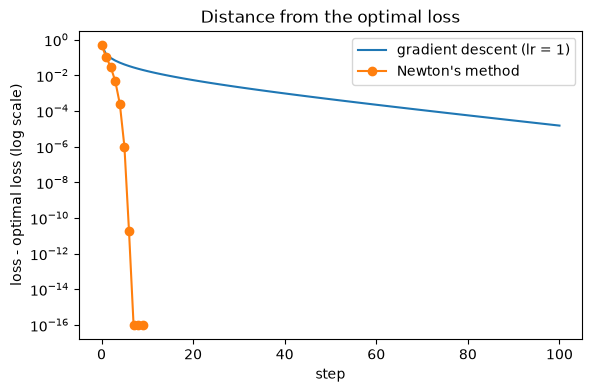

In [6]:
_, gd_losses = gradient_descent(lambda w: bce(Xcb, yc, w), lambda w: bce_grad(Xcb, yc, w),
                                np.zeros(3), lr=1.0, n_steps=100)
best = newton_losses[-1]

fig, ax = plt.subplots(figsize=(6.5, 4))
# Clip at 1e-16 so steps where the gap is exactly 0 still show on the log scale
ax.semilogy(np.maximum(gd_losses - best, 1e-16), label="gradient descent (lr = 1)")
ax.semilogy(np.maximum(newton_losses - best, 1e-16), "o-", label="Newton's method")
ax.set(title="Distance from the optimal loss", xlabel="step", ylabel="loss - optimal loss (log scale)")
ax.legend()
plt.show()

Gradient descent follows a straight line on the log scale: the error shrinks by a constant factor per step (linear convergence), and it is still about $10^{-4}$ above the optimum after 100 steps. Newton's method uses the curvature, roughly doubles the number of correct digits per step (quadratic convergence) and reaches floating-point precision by step 7. Each Newton step costs more, though: it solves a $d \times d$ linear system, $O(nd^2 + d^3)$ against $O(nd)$ for a gradient step.

### 5. Separable data

Move the two clouds far apart, so a line separates them perfectly, and track $\lVert \mathbf{w} \rVert$ during gradient descent on both datasets.

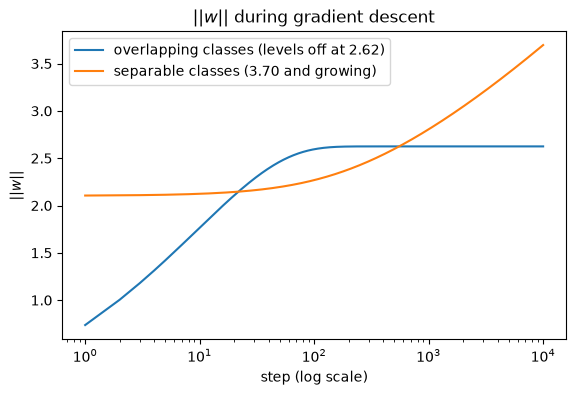

In [7]:
def weight_norm_path(X, y, n_steps=10_000, lr=1.0):
    """||w|| after every gradient descent step."""
    w = np.zeros(X.shape[1])
    norms = []
    for _ in range(n_steps):
        w = w - lr * bce_grad(X, y, w)
        norms.append(np.linalg.norm(w))
    return np.array(norms)


norms_overlap = weight_norm_path(Xcb, yc)
norms_separable = weight_norm_path(Xsb, yc)

steps = np.arange(1, len(norms_overlap) + 1)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogx(steps, norms_overlap, label=f"overlapping classes (levels off at {norms_overlap[-1]:.2f})")
ax.semilogx(steps, norms_separable, label=f"separable classes ({norms_separable[-1]:.2f} and growing)")
ax.set(title="$||w||$ during gradient descent", xlabel="step (log scale)", ylabel="$||w||$")
ax.legend()
plt.show()

On overlapping data, $\lVert \mathbf{w} \rVert$ levels off at the optimum. On separable data it keeps growing: once every point is classified correctly, making the sigmoid steeper always lowers the loss, so there is no finite minimum (in theory $\lVert \mathbf{w} \rVert$ grows like the log of the number of steps; Soudry et al., 2018). Regularisation, adding $\lambda \lVert \mathbf{w} \rVert^2$ to the loss, or early stopping prevents this.

## Check against reference

Each check compares my implementation with an independent reference, so a mistake in the maths or the code shows up as a failed assert:

- **Linear regression:** the closed-form weights against scikit-learn's `LinearRegression`, and gradient descent against the closed form.
- **Logistic regression:** Newton's method against scikit-learn's `LogisticRegression` with regularisation turned off (`C=np.inf`), comparing weights, probabilities, predicted classes and the loss (`log_loss`); then gradient descent against Newton.
- **Derivatives:** the gradients and Hessian from the maths section against finite differences, $\frac{\partial L}{\partial w_j} \approx \frac{L(\mathbf{w} + \epsilon \mathbf{e}_j) - L(\mathbf{w} - \epsilon \mathbf{e}_j)}{2\epsilon}$.
- **Numerical stability:** the sigmoid at $z = \pm 1000$, without overflow.

The logistic regression data has label noise, so the classes overlap. On separable data the unregularised optimum doesn't exist (see experiment 5), so there would be nothing to compare against.

In [8]:
from sklearn.datasets import make_classification, make_regression
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import log_loss

def numerical_grad(f, w, eps=1e-6):
    """Central finite differences: (f(w + eps e_j) - f(w - eps e_j)) / (2 eps) for each j."""
    grad = np.zeros_like(w)
    for j in range(len(w)):
        e = np.zeros_like(w)
        e[j] = eps
        grad[j] = (f(w + e) - f(w - e)) / (2 * eps)
    return grad

rng = np.random.default_rng(0)

# Linear regression
X, y = make_regression(n_samples=200, n_features=5, noise=10.0, random_state=0)
Xb = add_bias(X)
ref = LinearRegression().fit(X, y)

w_closed = linreg_closed_form(Xb, y)
np.testing.assert_allclose(w_closed[:-1], ref.coef_, rtol=1e-8)
np.testing.assert_allclose(w_closed[-1], ref.intercept_, rtol=1e-8)

w_gd, _ = gradient_descent(lambda w: mse(Xb, y, w), lambda w: mse_grad(Xb, y, w),
                           np.zeros(Xb.shape[1]), lr=0.1, n_steps=500)
np.testing.assert_allclose(w_gd, w_closed, atol=1e-6)

w = rng.normal(size=Xb.shape[1])
np.testing.assert_allclose(mse_grad(Xb, y, w), numerical_grad(lambda v: mse(Xb, y, v), w), rtol=1e-5)

# Logistic regression. flip_y adds label noise so the classes can't be separated perfectly;
# on separable data the unregularised optimum doesn't exist.
X, y = make_classification(n_samples=300, n_features=4, n_informative=3, n_redundant=0,
                           flip_y=0.1, random_state=0)
Xb = add_bias(X)
ref = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10_000).fit(X, y)  # C=inf: no regularisation

w_newton, _ = logreg_newton(Xb, y)
np.testing.assert_allclose(w_newton[:-1], ref.coef_[0], atol=1e-6)
np.testing.assert_allclose(w_newton[-1], ref.intercept_[0], atol=1e-6)
np.testing.assert_allclose(predict_proba(Xb, w_newton), ref.predict_proba(X)[:, 1], atol=1e-6)
np.testing.assert_array_equal(predict_class(Xb, w_newton), ref.predict(X))
np.testing.assert_allclose(bce(Xb, y, w_newton), log_loss(y, ref.predict_proba(X)), rtol=1e-6)

w_gd, _ = gradient_descent(lambda w: bce(Xb, y, w), lambda w: bce_grad(Xb, y, w),
                           np.zeros(Xb.shape[1]), lr=1.0, n_steps=2000)
np.testing.assert_allclose(w_gd, w_newton, atol=1e-6)

w = rng.normal(size=Xb.shape[1])
np.testing.assert_allclose(bce_grad(Xb, y, w), numerical_grad(lambda v: bce(Xb, y, v), w), rtol=1e-5, atol=1e-8)
hessian_numeric = np.array([numerical_grad(lambda v: bce_grad(Xb, y, v)[j], w) for j in range(len(w))])
np.testing.assert_allclose(bce_hessian(Xb, w), hessian_numeric, rtol=1e-5, atol=1e-8)

# The sigmoid must not overflow, and must reach its limits exactly
with np.errstate(over="raise"):
    np.testing.assert_array_equal(sigmoid(np.array([-1000.0, 0.0, 1000.0])), [0.0, 0.5, 1.0])

print("All checks passed")

All checks passed


## Questions to test yourself

**1. Why is logistic regression called *regression* if it's used for classification?**

It is a linear regression on the log-odds, $\log \frac{p}{1 - p} = \mathbf{w}^\top \mathbf{x}$. It only becomes a classifier when you threshold $p$.

- *Follow-up: what threshold would you use if a false negative costs ten times more than a false positive?* Predict positive whenever the expected cost of saying negative is higher: $10p > 1 - p$, so $p > 1/11 \approx 0.09$, not 0.5.

**2. Why not fit a classifier with linear regression, or a sigmoid with squared error?**

Linear regression's outputs aren't probabilities, and points far on the correct side still pull the line. A sigmoid with squared error fixes the outputs, but its loss is non-convex and its gradient, $(p - y) p (1 - p) \mathbf{x}$, vanishes when the model is confidently wrong. The cross-entropy gradient is simply $(p - y) \mathbf{x}$.

**3. When do the normal equations fail, and what do you do instead?**

When $\mathbf{X}^\top \mathbf{X}$ is singular: some features are exact linear combinations of others, or there are more features than samples ($d > n$). Use the pseudo-inverse (`np.linalg.lstsq` returns the minimum-norm solution) or add ridge regularisation, which makes $\mathbf{X}^\top \mathbf{X} + \lambda \mathbf{I}$ invertible.

- *Follow-up: even when it is invertible, why not compute the inverse explicitly?* Inverting is slower and less accurate than solving the system. Forming $\mathbf{X}^\top \mathbf{X}$ at all squares the condition number, so for badly conditioned data use QR or SVD on $\mathbf{X}$ directly, as `np.linalg.lstsq` does.

**4. What does linear regression assume?**

Computing the least-squares fit assumes nothing beyond $\mathbf{X}^\top \mathbf{X}$ being invertible. The assumptions matter for interpreting it: a linear relationship, errors with mean zero given the features, independent errors and constant variance. Under these, least squares is the best linear unbiased estimator (the Gauss–Markov theorem). Normally distributed errors are only needed for exact confidence intervals and p-values in small samples.

- *Follow-up: what happens if two features are highly correlated?* The predictions are still fine, but the individual coefficients become unstable: the data can't tell the two features apart, so their weights can swing a lot from one sample to the next.

**5. How do you interpret a logistic regression coefficient?**

Increasing feature $j$ by one unit, with the others fixed, multiplies the odds $\frac{p}{1 - p}$ by $e^{w_j}$.

- *Follow-up: if $w_j = 0.7$, does the probability double?* No. $e^{0.7} \approx 2$, so the odds double. How much the probability changes depends on where it starts: from 0.5 it goes to 0.67, but from 0.01 only to about 0.02.

**6. What happens to logistic regression on perfectly separable data, and how would you notice?**

The maximum-likelihood weights don't exist: scaling $\mathbf{w}$ up always lowers the loss, so the weights grow without limit (experiment 5). The signs are very large coefficients, probabilities of exactly 0 or 1, convergence warnings, and a singular Hessian in Newton's method. Regularisation or early stopping fixes it.

**7. Closed form, Newton's method or gradient descent: when would you use each?**

The closed form for linear regression with a moderate number of features. Newton's method for logistic regression when $d$ is small to moderate: it needs few steps, but each costs $O(nd^2 + d^3)$. Gradient descent, or its stochastic version, when $n$ or $d$ is large.

- *Follow-up: how do you choose the learning rate?* For linear regression it must satisfy $\eta < 2 / \lambda_{\max}$ (experiment 2). Standardising the features makes the Hessian better conditioned, so one learning rate works well in every direction.

**8. Why standardise features?**

Gradient descent converges faster because the loss surface becomes rounder, regularisation then penalises every feature on the same scale, and the coefficients become comparable. The predictions of the unregularised closed-form solution don't change.

**9. What does $R^2$ measure, and when is it misleading?**

The fraction of the variance in $y$ that the model explains, $R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$. On training data it can only go up when you add features, so compare models on held-out data or use adjusted $R^2$. A high $R^2$ also says nothing about causation.

**10. Business case: a regression across 200 stores shows that each extra member of staff is associated with £5,000 more weekly revenue. Should the client hire more staff?**

Not on this evidence alone. The coefficient is an association: busy stores may get more staff because they are busy (reverse causality), and location or store size may drive both (confounding). Recommend a test before a roll-out.

- *Follow-up: how would you test it?* Run a pilot: add staff in a randomly chosen group of stores, keep a similar group as a control, and compare the change in revenue. Randomising which stores get the extra staff removes the confounders.

## Gotchas

- **scikit-learn regularises logistic regression by default** (`C=1.0`). For an unregularised fit, as in this notebook, use `LogisticRegression(C=np.inf)`; `penalty=None` is deprecated since scikit-learn 1.8.
- **Don't invert $\mathbf{X}^\top \mathbf{X}$.** Solve the system instead, and with collinear features or $d > n$ use `np.linalg.lstsq` or ridge regularisation.
- **Naive formulas overflow.** `np.exp(-z)` overflows for large negative `z`, and the textbook cross-entropy takes `log(0)` when a probability rounds to 0 or 1. Use the stable forms from the implementation: the `tanh` identity and `np.logaddexp`.
- **Separable data has no unregularised optimum.** The weights grow forever and Newton's method breaks down; regularise or stop early.
- **Squared error is sensitive to outliers.** One point can tilt the line (experiment 1). Consider a robust loss such as the absolute error or the Huber loss.
- **Unscaled features slow gradient descent down.** The largest eigenvalue of the Hessian caps the learning rate, so standardise the features first.
- **Coefficients are associations, not causal effects.** "Holding the other features fixed" only holds inside the model; confounding and reverse causality still apply.
- **Odds are not probabilities.** $e^{w_j}$ multiplies the odds; the change in probability depends on where it starts.
- **0.5 is not always the right threshold.** Choose it from the cost of each kind of mistake and the class balance.
- **Correlated features make coefficients unstable**, even when the predictions are fine.
- **Don't extrapolate.** A linear trend fitted on one range of the data says little about values outside it.

## References

**Textbooks**

- James, G., Witten, D., Hastie, T. and Tibshirani, R. (2021). *An Introduction to Statistical Learning*, 2nd ed. Springer. Chapters 3 (linear regression) and 4 (classification). The gentlest starting point.
- Hastie, T., Tibshirani, R. and Friedman, J. (2009). *The Elements of Statistical Learning*, 2nd ed. Springer. Chapters 3 and 4.
- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer. Chapters 3 and 4, including Newton's method for logistic regression (iterative reweighted least squares, section 4.3.3).

**Papers mentioned in this notebook**

- Alain, G. and Bengio, Y. (2016). Understanding intermediate layers using linear classifier probes. arXiv:1610.01644.
- Deng, A., Xu, Y., Kohavi, R. and Walker, T. (2013). Improving the sensitivity of online controlled experiments by utilizing pre-experiment data. *WSDM*. (CUPED)
- Fama, E. F. and French, K. R. (1993). Common risk factors in the returns on stocks and bonds. *Journal of Financial Economics*, 33(1), 3–56.
- McMahan, H. B. et al. (2013). Ad click prediction: a view from the trenches. *KDD*.
- Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. In *Advances in Large Margin Classifiers*. MIT Press.
- Soudry, D., Hoffer, E., Nacson, M. S., Gunasekar, S. and Srebro, N. (2018). The implicit bias of gradient descent on separable data. *Journal of Machine Learning Research*, 19.

**Documentation**

- scikit-learn: [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) and [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).